## 6. Mô hình phân loại dự đoán rủi ro điểm đánh giá thấp (review_score ≤ 2)

Mục này xây dựng mô hình Random Forest Classifier kết hợp kỹ thuật Threshold Tuning để nhận diện các đơn hàng có nguy cơ nhận đánh giá thấp (1–2 sao), so sánh với mô hình nền Logistic Regression và phân tích các yếu tố vận hành ảnh hưởng lớn nhất đến sự hài lòng của khách hàng.

### 6.1 Đọc dữ liệu

**Mục đích:** Nạp dữ liệu đặc trưng đơn hàng và đánh giá từ view phân tích cơ sở `v_review_order_features` (định nghĩa trong `sql/03_queries.sql`) từ cơ sở dữ liệu SQLite để phục vụ bài toán phân loại.

Cell dưới kết nối cơ sở dữ liệu `olist.db`, nạp dữ liệu vào DataFrame, xử lý giá trị thiếu cho biến phương thức thanh toán và kiểm tra kích thước bảng.

In [1]:
import sqlite3
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Đọc dữ liệu từ SQLite database
def locate_db() -> Path:
    candidates = [
        Path(r"c:\ADY291c-AI2107-Group2\data\olist.db"),
        Path(r"c:\ADY291c-AI2107-Group2\scripts\database\olist.db"),
        Path("../../data/olist.db"),
        Path("../data/olist.db")
    ]
    for p in candidates:
        if p.exists() and p.stat().st_size > 0:
            return p
    raise FileNotFoundError("Không tìm thấy tệp olist.db hợp lệ.")

conn = sqlite3.connect(locate_db())
df = pd.read_sql_query("SELECT * FROM v_review_order_features", conn)
conn.close()

# 2. Xử lý giá trị thiếu
df['first_payment_type'] = df['first_payment_type'].fillna('unknown')

print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
print(f"Số lượng giá trị thiếu: {df.isna().sum().sum()}")

Kích thước dữ liệu: 95,329 dòng, 21 cột
Số lượng giá trị thiếu: 0


### 6.2 Biến mục tiêu và biến đầu vào

**Nguồn dữ liệu:** View `v_review_order_features` (định nghĩa trong `sql/03_queries.sql`, chỉ gồm các đơn hàng đã giao thành công và có review) tổng hợp sẵn dữ liệu cấp đơn hàng từ các bảng `orders`, `order_items`, `order_payments`, `order_reviews` và `customers`.

**Biến mục tiêu ($y$):** Cột gốc `review_score` trong view. Nhãn nhị phân rủi ro điểm thấp:
- **Lớp 1 (Rủi ro điểm thấp):** `review_score` ≤ 2 (đánh giá 1–2 sao phản ánh khách hàng thất vọng nghiêm trọng, cần can thiệp sớm).
- **Lớp 0 (Bình thường / Tích cực):** `review_score` ≥ 3 (đánh giá 3–5 sao).
- **Phân bố nhãn:** 12,177 đơn thuộc lớp `1` (12.77%) và 83,152 đơn thuộc lớp `0` (87.23%); dữ liệu mất cân bằng nên chất lượng mô hình được đánh giá đa chiều qua `Precision`, `Recall`, `F1-score` và `PR-AUC` bên cạnh `ROC-AUC`.

**Biến đầu vào ($X$): 12 biến** được trích xuất từ view `v_review_order_features` (loại bỏ khóa định danh `order_id` và chuỗi mốc thời gian `purchase_year_month`), gồm **2 biến phân loại** và **10 biến số học**:

- **Biến phân loại (2 biến):**
  - `customer_state`: Bang của khách hàng (27 bang Brazil).
  - `first_payment_type`: Phương thức thanh toán ở giao dịch đầu tiên (`credit_card`, `boleto`, `debit_card`, `voucher`, `unknown`).

- **Biến số học (10 biến):**
  - *Thời gian giao vận & độ trễ:* `delivery_days` (số ngày giao thực tế), `estimated_days` (số ngày giao dự kiến), `delay_days` (chênh lệch ngày giao so với hạn), `is_late` (cờ trễ hẹn: 1 nếu giao trễ, 0 nếu đúng/sớm hạn).
  - *Quy mô đơn hàng:* `item_count` (tổng số mặt hàng trong đơn), `seller_count` (số người bán tham gia đơn).
  - *Giá trị & chi phí:* `total_item_price` (tổng giá trị tiền hàng), `total_freight` (tổng phí vận chuyển), `freight_to_price_pct` (tỷ lệ 100 × phí ship / giá hàng).
  - *Thanh toán:* `max_installments` (số kỳ trả góp tối đa).

Cell dưới tạo nhãn $y$, tách ma trận $X$ gồm 12 đặc trưng và thống kê phân bố lớp mục tiêu.


In [2]:
# 1. Định nghĩa biến mục tiêu nhị phân y từ cột review_score
y = (df['review_score'] <= 2).astype(int)

# 2. Tách biến đầu vào X và phân nhóm đặc trưng từ v_review_order_features
cat_cols = ['customer_state', 'first_payment_type']
num_cols = [
    'delivery_days', 'estimated_days', 'delay_days', 'is_late',
    'item_count', 'seller_count', 'total_item_price', 'total_freight',
    'freight_to_price_pct', 'max_installments'
]
X = df[cat_cols + num_cols]

# 3. Thống kê phân bố nhãn
target_dist = pd.DataFrame({
    'Lớp Mục Tiêu (y)': ['0 (Bình thường: ≥ 3 sao)', '1 (Nguy cơ thấp: ≤ 2 sao)'],
    'Số Lượng Đơn': [int((y == 0).sum()), int((y == 1).sum())],
    'Tỷ Lệ (%)': [round(float((y == 0).mean() * 100), 2), round(float((y == 1).mean() * 100), 2)]
})
display(target_dist)
print(f"Tổng số đặc trưng đầu vào X: {X.shape[1]} ({len(cat_cols)} phân loại, {len(num_cols)} số học)")

,Lớp Mục Tiêu (y),Số Lượng Đơn,Tỷ Lệ (%)
0,0 (Bình thường: ≥ 3 sao),83152,87.23
1,1 (Nguy cơ thấp: ≤ 2 sao),12177,12.77


Tổng số đặc trưng đầu vào X: 12 (2 phân loại, 10 số học)


### 6.3 Chia tập train, validation và test

**Phương pháp:**
- Tách 80% Train và 20% Test, sử dụng `stratify=y` để bảo toàn tỷ lệ lớp thiểu số (~12.77%).
- Tách tiếp 20% từ tập Train làm tập Validation nhằm phục vụ tinh chỉnh ngưỡng phân loại mà không gây rò rỉ dữ liệu (data leakage) sang tập Test.
- Cố định `random_state = 42` để đảm bảo tính tái lập.

Cell dưới phân chia dữ liệu và hiển thị kích thước các tập.

In [3]:
# 1. Phân chia tập Train (80%) và Test (20%) phân tầng
idx_train, idx_test = train_test_split(
    df.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# 2. Tách tập Validation từ tập Train
idx_tr2, idx_val = train_test_split(
    idx_train, test_size=0.20, stratify=y.loc[idx_train], random_state=RANDOM_STATE
)

X_train, y_train = X.loc[idx_train], y.loc[idx_train]
X_test, y_test = X.loc[idx_test], y.loc[idx_test]

# 3. Hàm đánh giá dùng chung cho các mô hình
def evaluate_model(name: str, y_true, y_pred, y_proba) -> dict:
    return {
        'Mô hình': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred),
        'Macro-F1': f1_score(y_true, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
        'PR-AUC': average_precision_score(y_true, y_proba)
    }

print(f"Train set: {X_train.shape[0]:,} dòng | Validation set: {len(idx_val):,} dòng | Test set: {X_test.shape[0]:,} dòng")

Train set: 76,263 dòng | Validation set: 15,253 dòng | Test set: 19,066 dòng


### 6.4 Mô hình nền: Logistic Regression

**Mục đích:** Tạo mốc so sánh cơ sở (Baseline). Nếu mô hình phức tạp hơn không vượt trội hơn mô hình tuyến tính thì không cần áp dụng.

**Phương pháp:** Chuẩn hóa biến số học với `StandardScaler`, mã hóa One-Hot biến phân loại và xử lý mất cân bằng lớp bằng `class_weight='balanced'`.

Cell dưới huấn luyện mô hình Logistic Regression, tính toán các chỉ số và vẽ ma trận nhầm lẫn trên tập Test tại ngưỡng mặc định 0.50.

,Mô hình,Accuracy,Precision,Recall,F1-score,Macro-F1,ROC-AUC,PR-AUC
0,Logistic Regression (Baseline),0.827074,0.375936,0.536345,0.442038,0.669860,0.750460,0.425671


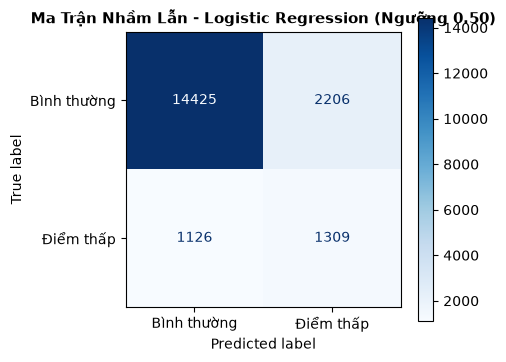

In [4]:
# 1. Pipeline Logistic Regression
pre_lr = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

pipeline_lr = Pipeline([
    ("preprocessor", pre_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

pipeline_lr.fit(X_train, y_train)

# 2. Dự đoán và đánh giá trên tập Test
y_proba_lr = pipeline_lr.predict_proba(X_test)[:, 1]
y_pred_lr = (y_proba_lr >= 0.50).astype(int)

model_results = []
res_lr = evaluate_model('Logistic Regression (Baseline)', y_test, y_pred_lr, y_proba_lr)
model_results.append(res_lr)
display(pd.DataFrame([res_lr]))

# 3. Ma trận nhầm lẫn
fig, ax = plt.subplots(figsize=(5, 4))
disp_lr = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred_lr), display_labels=['Bình thường', 'Điểm thấp'])
disp_lr.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Ma Trận Nhầm Lẫn - Logistic Regression (Ngưỡng 0.50)', fontsize=11, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

### 6.5 Mô hình Random Forest

**Phương pháp:** Rừng gồm 200 cây quyết định, `min_samples_leaf=20`, cân bằng mẫu bằng `class_weight='balanced_subsample'`.
- Quét tìm ngưỡng quyết định tối ưu trên tập **Validation** theo chỉ số `Macro-F1`.
- **Lý do chọn:** Tự động bắt quan hệ phi tuyến và tương tác đa biến giữa thời gian giao, độ trễ và số lượng hàng mà không yêu cầu chuẩn hóa dữ liệu.

Cell dưới huấn luyện Random Forest, tối ưu ngưỡng trên tập validation, đánh giá với cả 2 ngưỡng trên tập test và hiển thị bảng so sánh tổng hợp.

Ngưỡng tối ưu trên tập Validation: 0.66


,Mô hình,Accuracy,Precision,Recall,F1-score,Macro-F1,ROC-AUC,PR-AUC
0,Logistic Regression (Baseline),0.827074,0.375936,0.536345,0.442038,0.669860,0.750460,0.425671
1,Random Forest (Ngưỡng 0.50),0.847425,0.421262,0.520739,0.465748,0.688376,0.755658,0.480421
2,Random Forest (Ngưỡng 0.66),0.888702,0.598490,0.390554,0.472664,0.705225,0.755658,0.480421


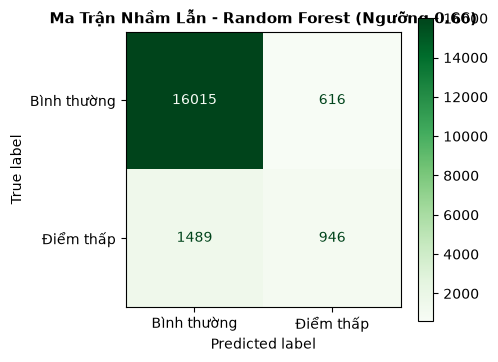

In [5]:
# 1. Pipeline Random Forest
pre_rf = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

pipeline_rf = Pipeline([
    ("preprocessor", pre_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
    ))
])

# 2. Tinh chỉnh ngưỡng trên tập Validation
pipeline_rf.fit(X.loc[idx_tr2], y.loc[idx_tr2])
val_probas = pipeline_rf.predict_proba(X.loc[idx_val])[:, 1]
threshold_grid = np.arange(0.30, 0.76, 0.02)
val_f1_scores = [f1_score(y.loc[idx_val], (val_probas >= t).astype(int), average="macro") for t in threshold_grid]
best_threshold = float(threshold_grid[int(np.argmax(val_f1_scores))])
print(f"Ngưỡng tối ưu trên tập Validation: {best_threshold:.2f}")

# 3. Huấn luyện lại trên toàn bộ tập Train và đánh giá trên Test
pipeline_rf.fit(X_train, y_train)
y_proba_rf = pipeline_rf.predict_proba(X_test)[:, 1]

# Đánh giá với ngưỡng mặc định 0.50 và ngưỡng tối ưu
y_pred_rf_default = (y_proba_rf >= 0.50).astype(int)
y_pred_rf_opt = (y_proba_rf >= best_threshold).astype(int)

res_rf_default = evaluate_model('Random Forest (Ngưỡng 0.50)', y_test, y_pred_rf_default, y_proba_rf)
res_rf_opt = evaluate_model(f'Random Forest (Ngưỡng {best_threshold:.2f})', y_test, y_pred_rf_opt, y_proba_rf)

model_results.extend([res_rf_default, res_rf_opt])
comparison_df = pd.DataFrame(model_results)
display(comparison_df)

# 4. Ma trận nhầm lẫn của Random Forest tại ngưỡng tối ưu
fig, ax = plt.subplots(figsize=(5, 4))
disp_rf = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred_rf_opt), display_labels=['Bình thường', 'Điểm thấp'])
disp_rf.plot(cmap='Greens', ax=ax, values_format='d')
plt.title(f'Ma Trận Nhầm Lẫn - Random Forest (Ngưỡng {best_threshold:.2f})', fontsize=11, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

### 6.6 Độ quan trọng của biến

**Mục đích:** Xác định các đặc trưng có ảnh hưởng lớn nhất đến khả năng dự báo của mô hình Random Forest.

**Phương pháp:** Sử dụng Permutation Importance trên tập mẫu Test (3,000 quan sát) để đo mức giảm trung bình của chỉ số ROC-AUC khi xáo trộn từng biến. Phương pháp này khách quan và không bị thiên lệch bởi số lượng giá trị duy nhất.

Cell dưới tính toán Permutation Importance, hiển thị bảng Top 10 và biểu đồ trực quan.

,Đặc Trưng,Mức Độ Quan Trọng (Mean ROC-AUC Drop)
0,item_count,0.0662
1,delay_days,0.0355
2,delivery_days,0.0249
3,customer_state,0.0063
4,total_freight,0.0036
5,seller_count,0.0032
6,first_payment_type,0.0030
7,max_installments,0.0023
8,freight_to_price_pct,0.0021
9,estimated_days,0.0020


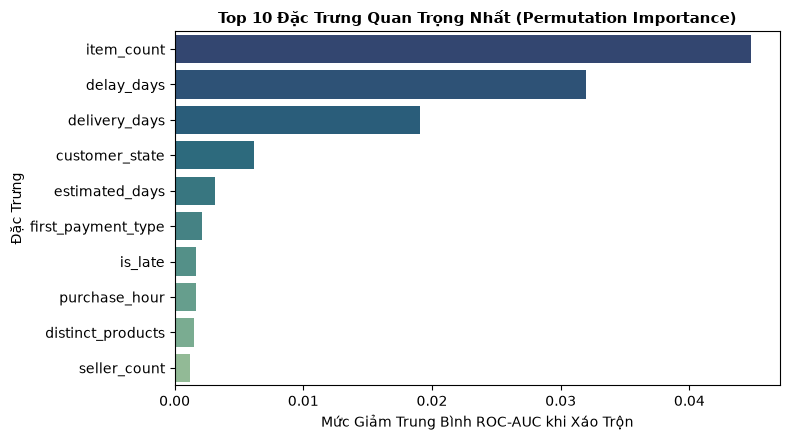

In [6]:
# 1. Tính toán Permutation Importance trên tập mẫu Test
test_sample_X = X_test.sample(n=3000, random_state=RANDOM_STATE)
test_sample_y = y_test.loc[test_sample_X.index]

perm_result = permutation_importance(
    pipeline_rf, test_sample_X, test_sample_y,
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)

# 2. Bảng Top 10 đặc trưng quan trọng nhất
importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
df_top10 = pd.DataFrame({
    'Đặc Trưng': importances.head(10).index,
    'Mức Độ Quan Trọng (Mean ROC-AUC Drop)': importances.head(10).values.round(4)
})
display(df_top10)

# 3. Trực quan hóa Top 10 đặc trưng
plt.figure(figsize=(8, 4.5))
sns.barplot(x=df_top10['Mức Độ Quan Trọng (Mean ROC-AUC Drop)'], y=df_top10['Đặc Trưng'], palette='crest_r')
plt.title('Top 10 Đặc Trưng Quan Trọng Nhất (Permutation Importance)', fontsize=11, fontweight='bold')
plt.xlabel('Mức Giảm Trung Bình ROC-AUC khi Xáo Trộn', fontsize=10)
plt.ylabel('Đặc Trưng', fontsize=10)
plt.tight_layout()
plt.show()

### 6.7 Kết luận và khuyến nghị

**So sánh mô hình:**

| Mô hình | Accuracy | Precision | Recall | F1-score | Macro-F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| Logistic Regression (0.50) | 0.8271 | 0.3759 | **0.5363** | 0.4420 | 0.6699 | 0.7505 | 0.4257 |
| Random Forest (0.50) | 0.8474 | 0.4213 | 0.5207 | 0.4657 | 0.6884 | **0.7557** | **0.4804** |
| Random Forest (0.66) | **0.8887** | **0.5985** | 0.3906 | **0.4727** | **0.7052** | **0.7557** | **0.4804** |

**Nhận định kỹ thuật:**
- **Đánh đổi giữa Precision và Recall:** Random Forest tại ngưỡng tối ưu 0.66 có **Precision vượt trội (59.8% so với 37.6%)**, giúp giảm thiểu tối đa các cảnh báo sai (False Positives). Ngược lại, Logistic Regression có **Recall cao hơn (53.6% so với 39.1%)**, bao phủ được nhiều đơn hàng điểm thấp hơn nhưng chấp nhận tỷ lệ báo động giả cao.
- **Lựa chọn mô hình:** Chọn **Random Forest (ngưỡng 0.66)** làm mô hình chính vì đạt cân bằng tổng thể tốt nhất (Macro-F1 đạt 0.7052, PR-AUC đạt 0.4804), giúp doanh nghiệp tập trung nguồn lực chăm sóc khách hàng vào các đơn hàng có rủi ro thực sự cao.

**Top biến có đóng góp nổi bật (từ view v_review_order_features):**
1. `item_count` (0.0662): Đơn hàng có nhiều sản phẩm tiềm ẩn độ phức tạp khi đóng gói, rủi ro giao thiếu và thời gian xử lý kéo dài.
2. `delay_days` (0.0355) & `delivery_days` (0.0249): Thời gian giao hàng thực tế và độ trễ hẹn là yếu tố chi phối mạnh mẽ nhất đến cảm nhận của người mua.
3. `customer_state` (0.0063) & `total_freight` (0.0036): Yếu tố vùng miền địa lý của khách hàng và chi phí vận chuyển có tác động phụ trợ đáng kể đến kỳ vọng dịch vụ.
*(Lưu ý: Mức độ quan trọng phản ánh liên kết thống kê trong mô hình dự báo, không khẳng định quan hệ nhân quả trực tiếp).*

**Khuyến nghị vận hành:**
- **Cảnh báo sớm:** Gắn cờ ưu tiên chăm sóc khách hàng cho các đơn hàng có xác suất rủi ro ≥ 0.66.
- **Xử lý chủ động:** Tự động gửi thông báo cập nhật lộ trình hoặc chính sách hỗ trợ khi đơn hàng phát sinh trễ hẹn (`delay_days > 0`) trước khi khách hàng để lại đánh giá.
- **Kiểm soát đóng gói:** Thiết lập quy trình kiểm tra chéo (checklist) cho đơn hàng có nhiều sản phẩm (`item_count ≥ 2`) để hạn chế thất lạc hoặc giao hàng rời rạc.